Technological Institute of the Philippines | Quezon City - Computer Engineering
--- | ---
Course Code: | CPE 027
Code Title: | Digital Signal Processing and Application
1st Semester | AY 2026-2027
<u>**Laboratory Activity 11** | **Simple Equalizer**
**Name** | Adrian Justin Bulambao
**Section** | CPE41S1
**Date Performed**: | October 11, 2026
**Date Submitted**: | October 11, 2026
**Instructor**: | Engr. Leah Belaya

<hr>

1. Download your favorite song and plot the first 20 seconds of it.

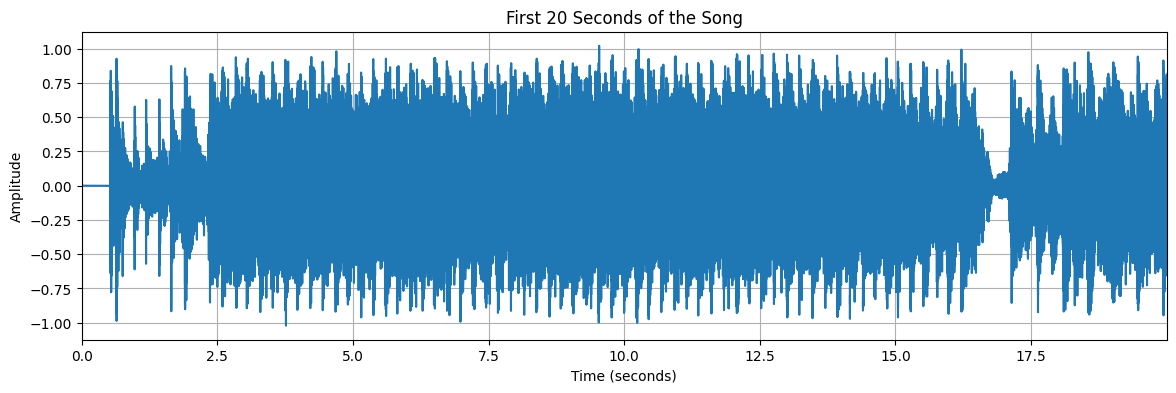

In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Load the song
file_path = "/content/drive/MyDrive/CPE 027 - DSP Files/LAB 11/Gracenote - When I Dream About You (Lyrics).mp3"

audio, sr = librosa.load(file_path, sr=None, mono=True)

# Extract the first 20 seconds
duration = 20
num_samples = min(len(audio), int(duration * sr))
signal = audio[:num_samples]

# Create time array
time = np.arange(len(signal)) / sr

# Plot the first 20 seconds
plt.figure(figsize=(14, 4))
plt.plot(time, signal)
plt.title("First 20 Seconds of the Song")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, time[-1])
plt.grid(True)
plt.show()

2. Sample the signal to appropriate number of samples to have set of arrays and quantized it.


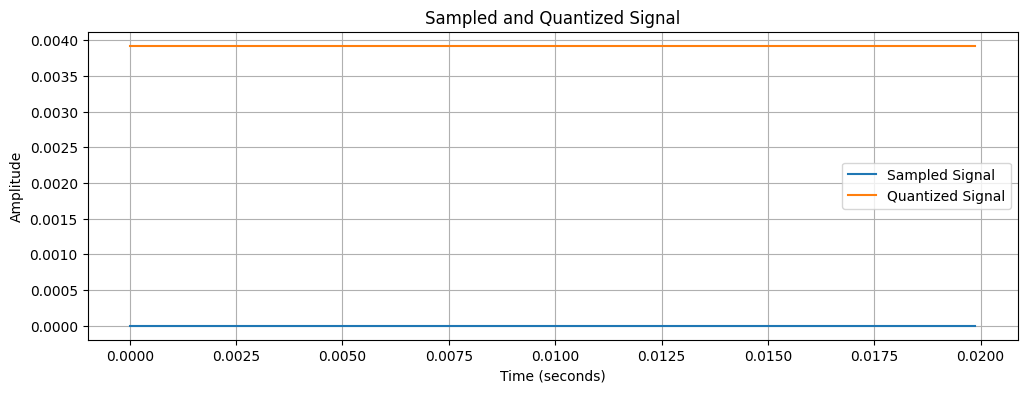

Sampling rate: 8000 Hz
Number of samples: 160000
Quantization levels: 256


In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

# Resample the first 20 seconds to 8 kHz
target_sr = 8000

sampled_signal = librosa.resample(
    signal,
    orig_sr=sr,
    target_sr=target_sr
)

sr = target_sr
time = np.arange(len(sampled_signal)) / sr

# Quantize to 8-bit resolution (256 levels)
levels = 256
normalized_signal = np.clip(sampled_signal, -1, 1)

quantized_signal = (
    np.round((normalized_signal + 1) * (levels - 1) / 2)
    * 2 / (levels - 1) - 1
)

# Plot a short segment to see the quantization levels
samples_to_plot = int(0.02 * sr)  # First 20 milliseconds

plt.figure(figsize=(12, 4))
plt.plot(time[:samples_to_plot],
         sampled_signal[:samples_to_plot],
         label="Sampled Signal")
plt.step(time[:samples_to_plot],
         quantized_signal[:samples_to_plot],
         where="mid",
         label="Quantized Signal")
plt.title("Sampled and Quantized Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

print("Sampling rate:", sr, "Hz")
print("Number of samples:", len(sampled_signal))
print("Quantization levels:", levels)

3. Perform digital FIR filter using Moving Average to smooth the sampled signal. Plot it.

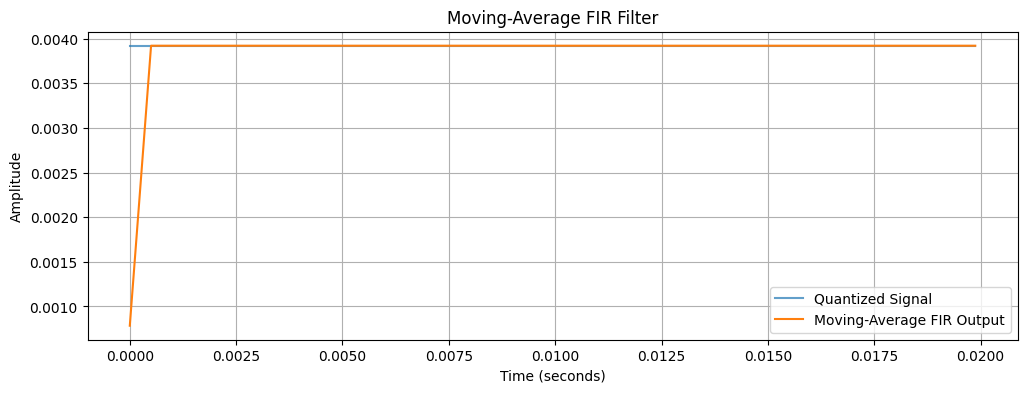

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter

# Create a 5-sample moving-average FIR filter
window_size = 5
fir_coefficients = np.ones(window_size) / window_size

# Apply the FIR filter
smoothed_signal = lfilter(
    fir_coefficients,
    1.0,
    quantized_signal
)

# Plot the first 20 milliseconds
samples_to_plot = int(0.02 * sr)

plt.figure(figsize=(12, 4))
plt.plot(time[:samples_to_plot],
         quantized_signal[:samples_to_plot],
         label="Quantized Signal",
         alpha=0.7)
plt.plot(time[:samples_to_plot],
         smoothed_signal[:samples_to_plot],
         label="Moving-Average FIR Output")
plt.title("Moving-Average FIR Filter")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

4. Transform this signal into frequency domain using FFT to see what frequencies are available in the signal.


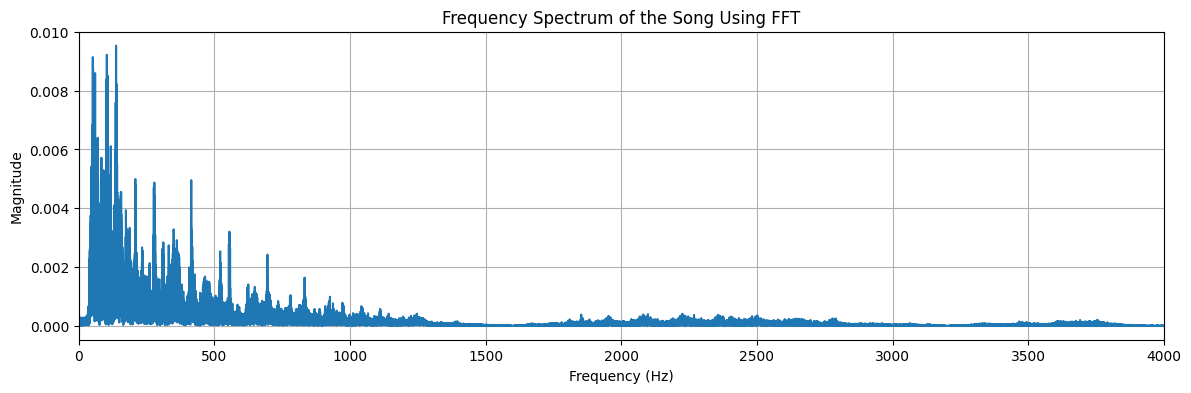

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Perform FFT
N = len(smoothed_signal)
fft_result = np.fft.rfft(smoothed_signal)
frequencies = np.fft.rfftfreq(N, d=1/sr)

# Calculate magnitude spectrum
magnitude = np.abs(fft_result) / N

# Plot frequency spectrum
plt.figure(figsize=(14, 4))
plt.plot(frequencies, magnitude)
plt.title("Frequency Spectrum of the Song Using FFT")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, sr / 2)
plt.grid(True)
plt.show()

5. Now, perform 3 digital filters (using either Windows-sinc or Chebyshev) with the following cut-off:

    a. low-pass filter: 300 Hz

    b. band-pass filter: 300-3400 Hz

    c. high-pass filter: 3400 Hz


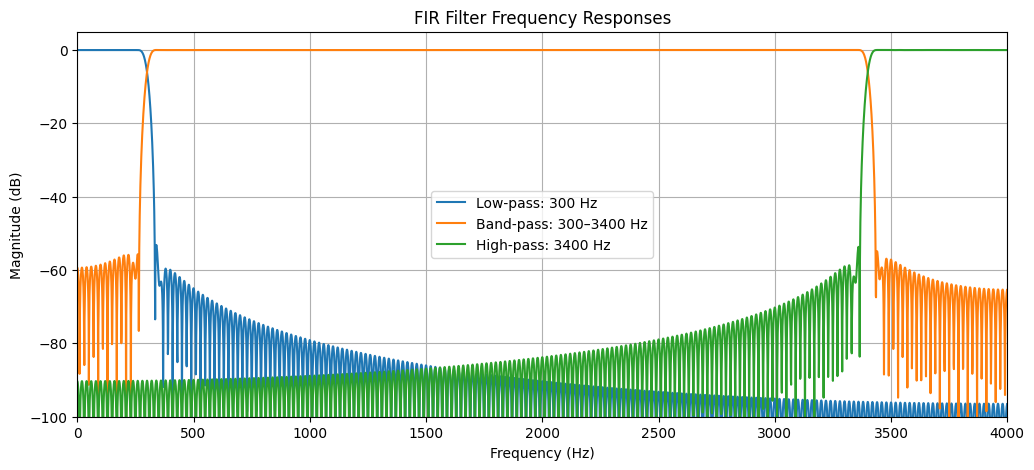

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz, fftconvolve

# Design FIR filters
num_taps = 401

lowpass_coeff = firwin(
    num_taps, 300, fs=sr, pass_zero="lowpass", window="hamming"
)

bandpass_coeff = firwin(
    num_taps, [300, 3400], fs=sr,
    pass_zero="bandpass", window="hamming"
)

highpass_coeff = firwin(
    num_taps, 3400, fs=sr, pass_zero="highpass", window="hamming"
)

# Apply the filters to the smoothed signal
lowpass_signal = fftconvolve(
    smoothed_signal, lowpass_coeff, mode="same"
)

bandpass_signal = fftconvolve(
    smoothed_signal, bandpass_coeff, mode="same"
)

highpass_signal = fftconvolve(
    smoothed_signal, highpass_coeff, mode="same"
)

# Plot the frequency responses of all three filters
plt.figure(figsize=(12, 5))

for coeff, label in [
    (lowpass_coeff, "Low-pass: 300 Hz"),
    (bandpass_coeff, "Band-pass: 300–3400 Hz"),
    (highpass_coeff, "High-pass: 3400 Hz")
]:
    f, h = freqz(coeff, worN=4096, fs=sr)
    plt.plot(f, 20 * np.log10(np.maximum(np.abs(h), 1e-8)),
             label=label)

plt.title("FIR Filter Frequency Responses")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, sr / 2)
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.show()

6. Transform each filtered frequency domain signal into time domain signal.

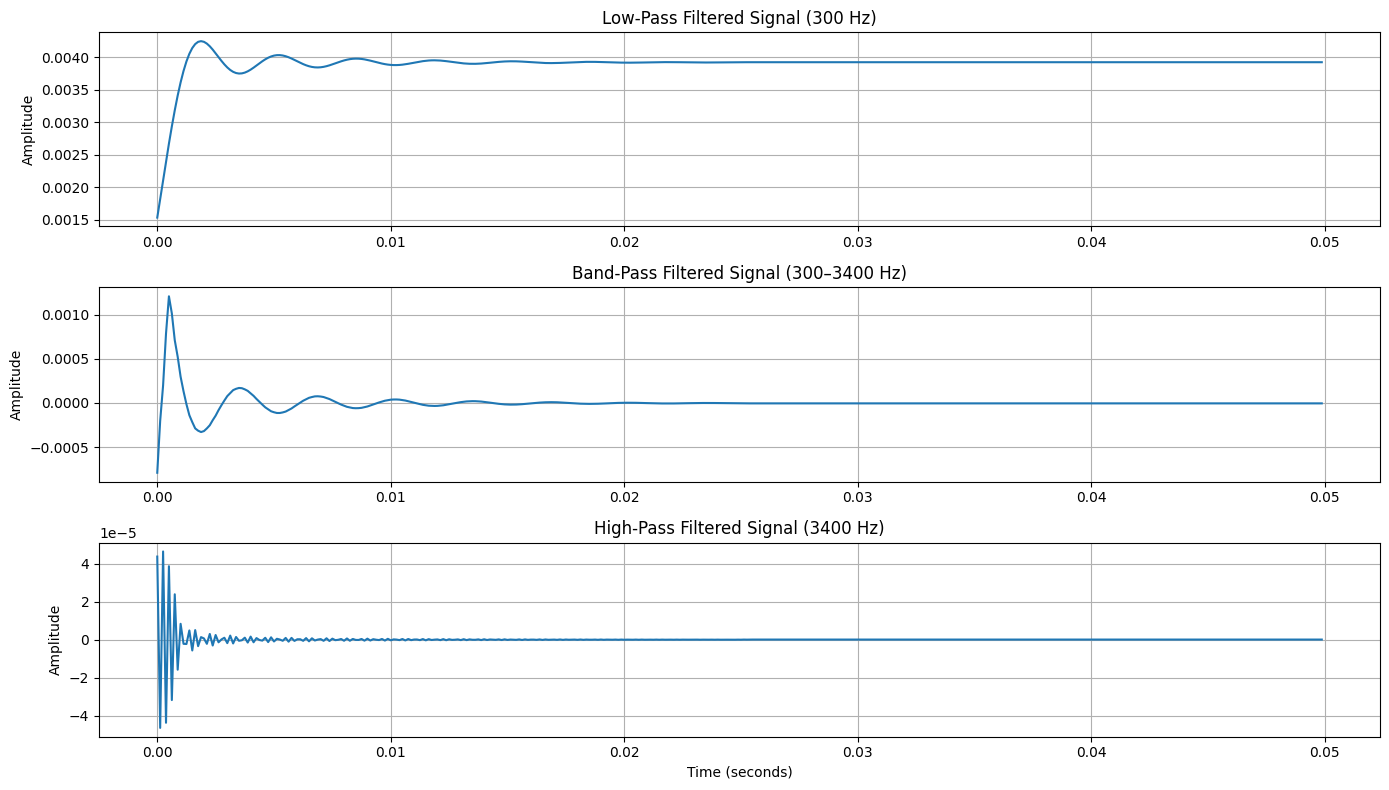

In [ ]:
import matplotlib.pyplot as plt

# Plot the first 50 milliseconds
samples_to_plot = int(0.05 * sr)

plt.figure(figsize=(14, 8))

plt.subplot(3, 1, 1)
plt.plot(time[:samples_to_plot],
         lowpass_signal[:samples_to_plot])
plt.title("Low-Pass Filtered Signal (300 Hz)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(time[:samples_to_plot],
         bandpass_signal[:samples_to_plot])
plt.title("Band-Pass Filtered Signal (300–3400 Hz)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(time[:samples_to_plot],
         highpass_signal[:samples_to_plot])
plt.title("High-Pass Filtered Signal (3400 Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

7. Then listen to this.

In [ ]:
from IPython.display import Audio, display

print("Original Song (First 20 Seconds)")
display(Audio(sampled_signal, rate=sr))

print("Smoothed Song - Moving-Average FIR")
display(Audio(smoothed_signal, rate=sr))

print("Low-Pass Filtered Song - 300 Hz")
display(Audio(lowpass_signal, rate=sr))

print("Band-Pass Filtered Song - 300 to 3400 Hz")
display(Audio(bandpass_signal, rate=sr))

print("High-Pass Filtered Song - 3400 Hz")
display(Audio(highpass_signal, rate=sr))

Original Song (First 20 Seconds)


Smoothed Song - Moving-Average FIR


Low-Pass Filtered Song - 300 Hz


Band-Pass Filtered Song - 300 to 3400 Hz


High-Pass Filtered Song - 3400 Hz
